# Graph-based RAG dan GenAI

Notebook ini melanjutkan hasil dari `02_Knowledge_Graph_Graph_RAG.ipynb`.

Notebook kedua berfokus pada pembentukan Knowledge Graph dan Graph Retrieval. Notebook ini berfokus pada pemanfaatan hasil retrieval sebagai konteks untuk **Graph-based RAG** dan penyusunan jawaban berbasis evidence.

## STEP 1 — Graph-based RAG + GenAI

Alur utama:

**Pertanyaan → Query Understanding → Graph Retrieval → Evidence → Grounded Context → GenAI → Jawaban + Evidence**

Tahap ini tidak membangun ulang Knowledge Graph. Data graph dan retrieval digunakan sebagai sumber fakta.

## 1. Import dan Kontrak Data

Notebook ini menggunakan hasil dari notebook sebelumnya. Agar dapat dijalankan secara mandiri, file hasil graph/retrieval dibaca dari folder kerja.

File yang diharapkan:

- `innovation_knowledge_graph.graphml`
- `knowledge_graph_nodes.csv`
- `knowledge_graph_edges.csv`

Jika notebook sebelumnya dijalankan dalam kernel yang sama, objek `G`, `retrieve_innovations`, `retrieve_profile_characteristics`, dan `build_retrieval_context` juga dapat digunakan langsung.

In [1]:
# ==============================================================
# 1.1 — IMPORT DAN LOAD GRAPH
# ==============================================================

import os
import json
import pandas as pd
import numpy as np
import networkx as nx
from pathlib import Path

BASE_DIR = Path.cwd()

graph_path = BASE_DIR / "innovation_knowledge_graph.graphml"
nodes_path = BASE_DIR / "knowledge_graph_nodes.csv"
edges_path = BASE_DIR / "knowledge_graph_edges.csv"

print("Working directory:", BASE_DIR)

if "G" not in globals():
    if graph_path.exists():
        G = nx.read_graphml(graph_path)
        print("Knowledge Graph berhasil dimuat dari:", graph_path)
    else:
        raise FileNotFoundError(
            "Knowledge Graph belum tersedia. Jalankan STEP 4 pada notebook 02 "
            "atau letakkan innovation_knowledge_graph.graphml di folder kerja."
        )
else:
    print("Menggunakan objek Knowledge Graph G dari kernel saat ini.")

print("Jumlah node:", G.number_of_nodes())
print("Jumlah edge:", G.number_of_edges())

Working directory: c:\KULIAH\Andro sems 7\Prosada\Prosada-Final
Knowledge Graph berhasil dimuat dari: c:\KULIAH\Andro sems 7\Prosada\Prosada-Final\innovation_knowledge_graph.graphml
Jumlah node: 1073
Jumlah edge: 5817


In [2]:
# ==============================================================
# 1.2 — LOAD TABLE HASIL GRAPH
# ==============================================================

if nodes_path.exists():
    kg_nodes = pd.read_csv(nodes_path)
    print("knowledge_graph_nodes.csv:", kg_nodes.shape)
else:
    kg_nodes = None
    print("knowledge_graph_nodes.csv tidak ditemukan; menggunakan G.")

if edges_path.exists():
    kg_edges = pd.read_csv(edges_path)
    print("knowledge_graph_edges.csv:", kg_edges.shape)
else:
    kg_edges = None
    print("knowledge_graph_edges.csv tidak ditemukan; menggunakan G.")

knowledge_graph_nodes.csv: (1073, 28)
knowledge_graph_edges.csv: (5817, 8)


## 2. Graph Retrieval sebagai Sumber Evidence

Graph Retrieval tidak menghasilkan jawaban. Retrieval hanya memilih fakta dan hubungan yang relevan terhadap pertanyaan.

Contoh:

**Pertanyaan**

> Apa karakteristik Profil Ekosistem Inovasi Wilayah 2?

**Retrieval**

`Profil → weighted characteristics`

**Evidence**

`Non Digital = 63.33%`

`Penerapan = 94.38%`

`Pendidikan = 84.60%`

Evidence inilah yang akan menjadi konteks bagi GenAI.

In [3]:
# ==============================================================
# 2.1 — FALLBACK RETRIEVAL FUNCTIONS
# ==============================================================

# Jika fungsi retrieval belum tersedia di kernel ini, definisikan
# versi sederhana yang bekerja langsung dari graph.

def _g_node_type(n):
    return str(G.nodes[n].get("type", ""))

def _g_name(n):
    d = G.nodes[n]
    keys = [
        "nama_profil", "nama_daerah", "judul_inovasi", "nama_opd",
        "nama_jenis", "nama_urusan", "nama_tahapan",
        "nama_bentuk", "nama_asta_cipta"
    ]
    for k in keys:
        if d.get(k) not in [None, ""]:
            return str(d[k])
    return str(n)

def _g_find(node_type, value):
    value = str(value).strip().lower()
    exact = []
    partial = []
    for n, d in G.nodes(data=True):
        if d.get("type") != node_type:
            continue
        name = _g_name(n).strip().lower()
        if name == value:
            exact.append(n)
        elif value in name:
            partial.append(n)
    return exact or partial

print("Graph retrieval utilities tersedia.")

Graph retrieval utilities tersedia.


## 3. Query Understanding

Pada tahap awal, query dibuat dalam bentuk parameter terstruktur. Tujuannya agar retrieval dapat diuji secara terpisah dari model bahasa.

Contoh struktur:

```text
profil   = Profil Ekosistem Wilayah 2
jenis    = Digital
urusan   = pendidikan
```

Tahap berikutnya dapat mengganti input terstruktur ini dengan hasil interpretasi LLM.

In [4]:
# ==============================================================
# 3.1 — QUERY SCHEMA
# ==============================================================

query_examples = [
    {
        "query_id": "Q01",
        "question": "Apa karakteristik Profil Ekosistem Inovasi Wilayah 2?",
        "intent": "profile_characteristics",
        "profil": None,
        "jenis": None,
        "urusan": None,
    },
    {
        "query_id": "Q02",
        "question": "Apa saja inovasi Digital pada urusan pendidikan dalam profil tertentu?",
        "intent": "innovation_filter",
        "profil": None,
        "jenis": "Digital",
        "urusan": "pendidikan",
    },
]

query_examples_df = pd.DataFrame(query_examples)
display(query_examples_df)

,query_id,question,intent,profil,jenis,urusan
0,Q01,Apa karakteristik Profil Ekosistem Inovasi Wil...,profile_characteristics,None,NaN,NaN
1,Q02,Apa saja inovasi Digital pada urusan pendidika...,innovation_filter,None,Digital,pendidikan


In [5]:
# ==============================================================
# 3.2 — RESOLVE PROFIL CONTOH DARI GRAPH
# ==============================================================

profile_nodes = [
    n for n, d in G.nodes(data=True)
    if d.get("type") == "ProfilEkosistemInovasi"
]

print("Jumlah ProfilEkosistemInovasi:", len(profile_nodes))

if profile_nodes:
    profile_options = pd.DataFrame([
        {"profil_id": n, "profil": _g_name(n)}
        for n in profile_nodes
    ])
    display(profile_options)
else:
    profile_options = pd.DataFrame()

Jumlah ProfilEkosistemInovasi: 3


,profil_id,profil
0,PROFILE_EKO_01,Profil Ekosistem Wilayah 1
1,PROFILE_EKO_02,Profil Ekosistem Wilayah 2
2,PROFILE_EKO_03,Profil Ekosistem Wilayah 3


## 4. Retrieval untuk Graph-based RAG

Retrieval dibedakan menjadi dua bentuk:

1. **Factual retrieval** — mengambil inovasi dan hubungan faktual.
2. **Profile retrieval** — mengambil karakteristik profil, termasuk weighted relationship.

Keduanya dapat digabungkan menjadi satu context.

In [6]:
# ==============================================================
# 4.1 — RETRIEVAL PROFILE CHARACTERISTICS
# ==============================================================

def graph_weighted_profile(profile_id):
    rows = []
    if profile_id not in G:
        return pd.DataFrame()

    for _, target, data in G.out_edges(profile_id, data=True):
        if data.get("weighted", False):
            rows.append({
                "profil_id": profile_id,
                "profil": _g_name(profile_id),
                "relationship": data.get("relation", ""),
                "target_id": target,
                "target": _g_name(target),
                "weight": float(data.get("weight", np.nan)),
                "percentage": float(data.get("percentage", np.nan)),
                "count": data.get("count", np.nan),
                "total": data.get("total", np.nan),
            })
    return pd.DataFrame(rows)

# Pilih profil yang tersedia untuk demo
demo_profile = profile_nodes[0] if profile_nodes else None
profile_weighted = graph_weighted_profile(demo_profile) if demo_profile else pd.DataFrame()

print("Profil demo:", demo_profile)
display(profile_weighted)

Profil demo: PROFILE_EKO_01


,profil_id,profil,relationship,target_id,target,weight,percentage,count,total
0,PROFILE_EKO_01,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,JENIS_03,Teknologi,0.46,46.0,23,50
1,PROFILE_EKO_01,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,JENIS_02,Non Digital,0.40,40.0,20,50
2,PROFILE_EKO_01,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,JENIS_01,Digital,0.14,14.0,7,50
3,PROFILE_EKO_01,Profil Ekosistem Wilayah 1,DOMINAN_URUSAN,URUSAN_012,kesehatan,0.66,66.0,33,50
4,PROFILE_EKO_01,Profil Ekosistem Wilayah 1,DOMINAN_URUSAN,URUSAN_027,pendidikan,0.34,34.0,17,50
5,PROFILE_EKO_01,Profil Ekosistem Wilayah 1,DOMINAN_TAHAPAN,TAHAPAN_02,Penerapan,1.00,100.0,50,50
6,PROFILE_EKO_01,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,BENTUK_02,Inovasi pelayanan publik,0.90,90.0,45,50
7,PROFILE_EKO_01,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,BENTUK_01,Inovasi Daerah lainnya sesuai dengan Urusan Pe...,0.06,6.0,3,50
8,PROFILE_EKO_01,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,BENTUK_03,Inovasi tata kelola pemerintahan daerah,0.04,4.0,2,50


In [7]:
# ==============================================================
# 4.2 — RETRIEVAL INOVASI BERBASIS GRAPH
# ==============================================================

def retrieve_innovations_basic(profil_id=None, jenis=None, urusan=None, limit=None):
    innovations = {
        n for n, d in G.nodes(data=True)
        if d.get("type") == "Inovasi"
    }

    if profil_id:
        ptype = _g_node_type(profil_id)

        if ptype == "ProfilEkosistemInovasi":
            daerah_ids = [
                u for u, _, d in G.in_edges(profil_id, data=True)
                if d.get("relation") == "TERMASUK_PROFIL_EKOSISTEM"
            ]
            profile_innovations = set()
            for daerah_id in daerah_ids:
                profile_innovations.update(
                    u for u, _, d in G.in_edges(daerah_id, data=True)
                    if d.get("relation") == "BERADA_DI"
                )
            innovations &= profile_innovations

        elif ptype == "ProfilKarakteristikInovasi":
            innovations &= {
                u for u, _, d in G.in_edges(profil_id, data=True)
                if d.get("relation") == "DICIRIKAN_PROFIL"
            }

    def filter_target(current, node_type, relation, value):
        if value is None:
            return current
        target_ids = _g_find(node_type, value)
        matched = set()
        for tid in target_ids:
            matched.update(
                u for u, _, d in G.in_edges(tid, data=True)
                if d.get("relation") == relation
            )
        return current & matched

    innovations = filter_target(innovations, "Jenis", "BERJENIS", jenis)
    innovations = filter_target(
        innovations, "Urusan", "MENANGANI_URUSAN", urusan
    )

    rows = []
    for iid in sorted(innovations):
        d = G.nodes[iid]
        daerah = [
            _g_name(v) for _, v, e in G.out_edges(iid, data=True)
            if e.get("relation") == "BERADA_DI"
        ]
        opd = [
            _g_name(v) for _, v, e in G.out_edges(iid, data=True)
            if e.get("relation") == "DIKELOLA_OLEH"
        ]
        jenis_list = [
            _g_name(v) for _, v, e in G.out_edges(iid, data=True)
            if e.get("relation") == "BERJENIS"
        ]
        urusan_list = [
            _g_name(v) for _, v, e in G.out_edges(iid, data=True)
            if e.get("relation") == "MENANGANI_URUSAN"
        ]
        tahap = [
            _g_name(v) for _, v, e in G.out_edges(iid, data=True)
            if e.get("relation") == "BERADA_DI_TAHAPAN"
        ]

        rows.append({
            "inovasi_id": iid,
            "judul": d.get("judul_inovasi", _g_name(iid)),
            "daerah": "; ".join(daerah),
            "opd": "; ".join(opd),
            "jenis": "; ".join(jenis_list),
            "urusan": "; ".join(urusan_list),
            "tahapan": "; ".join(tahap),
            "kematangan": d.get("kematangan", ""),
        })

    result = pd.DataFrame(rows)
    return result.head(limit) if limit else result

print("Retrieval innovation function siap.")

Retrieval innovation function siap.


## 5. Evidence Assembly

Evidence disusun tanpa interpretasi. Setiap fakta memiliki sumber node, relationship, target, dan property yang tersedia.

Prinsipnya:

> **Jika tidak terdapat evidence pada graph, fakta tersebut tidak dimasukkan ke context.**

In [8]:
# ==============================================================
# 5.1 — BUILD EVIDENCE
# ==============================================================

def build_graph_evidence(profile_id=None, jenis=None, urusan=None, limit=20):
    evidence = {
        "query_scope": {
            "profile_id": profile_id,
            "jenis": jenis,
            "urusan": urusan
        },
        "profile_evidence": [],
        "innovation_evidence": [],
        "paths": []
    }

    if profile_id:
        weighted = graph_weighted_profile(profile_id)
        if not weighted.empty:
            for _, r in weighted.iterrows():
                evidence["profile_evidence"].append({
                    "source_id": r["profil_id"],
                    "source": r["profil"],
                    "relationship": r["relationship"],
                    "target_id": r["target_id"],
                    "target": r["target"],
                    "weight": r["weight"],
                    "percentage": r["percentage"],
                    "count": r["count"],
                    "total": r["total"],
                })

    results = retrieve_innovations_basic(
        profil_id=profile_id,
        jenis=jenis,
        urusan=urusan,
        limit=limit
    )

    if not results.empty:
        for _, r in results.iterrows():
            evidence["innovation_evidence"].append(r.to_dict())

            if profile_id:
                for did in [
                    v for _, v, e in G.out_edges(r["inovasi_id"], data=True)
                    if e.get("relation") == "BERADA_DI"
                ]:
                    if any(
                        e.get("relation") == "TERMASUK_PROFIL_EKOSISTEM"
                        for _, v, e in G.out_edges(did, data=True)
                        if v == profile_id
                    ):
                        evidence["paths"].append(
                            f"{profile_id} → {did} → {r['inovasi_id']}"
                        )

    return evidence

demo_evidence = build_graph_evidence(
    profile_id=demo_profile,
    jenis=None,
    urusan=None,
    limit=20
)

print("Profile evidence:", len(demo_evidence["profile_evidence"]))
print("Innovation evidence:", len(demo_evidence["innovation_evidence"]))
print("Traversal paths:", len(demo_evidence["paths"]))

Profile evidence: 9
Innovation evidence: 20
Traversal paths: 20


In [9]:
# ==============================================================
# 5.2 — BUILD GROUNDED CONTEXT
# ==============================================================

def build_grounded_context(evidence):
    lines = [
        "=== GRAPH-BASED RAG CONTEXT ===",
        "",
        "RULE:",
        "Gunakan hanya informasi yang tersedia pada evidence berikut.",
        "Jika informasi tidak tersedia, nyatakan bahwa evidence tidak ditemukan.",
        ""
    ]

    lines.append("PROFILE EVIDENCE:")
    if evidence["profile_evidence"]:
        for e in evidence["profile_evidence"]:
            lines.append(
                f"- {e['source']} | {e['relationship']} | "
                f"{e['target']} | weight={e['weight']:.4f} | "
                f"percentage={e['percentage']:.2f}% | "
                f"count={e['count']}/{e['total']}"
            )
    else:
        lines.append("- Tidak ada profile evidence.")

    lines.append("")
    lines.append("INNOVATION EVIDENCE:")
    if evidence["innovation_evidence"]:
        for e in evidence["innovation_evidence"]:
            lines.append(
                f"- {e['inovasi_id']} | {e['judul']} | "
                f"Daerah={e['daerah']} | OPD={e['opd']} | "
                f"Jenis={e['jenis']} | Urusan={e['urusan']} | "
                f"Tahapan={e['tahapan']} | Kematangan={e['kematangan']}"
            )
    else:
        lines.append("- Tidak ada innovation evidence.")

    lines.append("")
    lines.append("TRAVERSAL PATHS:")
    if evidence["paths"]:
        lines.extend([f"- {p}" for p in evidence["paths"]])
    else:
        lines.append("- Tidak ada path yang tercatat.")

    return "".join(lines)

grounded_context = build_grounded_context(demo_evidence)
print(grounded_context[:10000])

=== GRAPH-BASED RAG CONTEXT ===RULE:Gunakan hanya informasi yang tersedia pada evidence berikut.Jika informasi tidak tersedia, nyatakan bahwa evidence tidak ditemukan.PROFILE EVIDENCE:- Profil Ekosistem Wilayah 1 | DOMINAN_JENIS | Teknologi | weight=0.4600 | percentage=46.00% | count=23/50- Profil Ekosistem Wilayah 1 | DOMINAN_JENIS | Non Digital | weight=0.4000 | percentage=40.00% | count=20/50- Profil Ekosistem Wilayah 1 | DOMINAN_JENIS | Digital | weight=0.1400 | percentage=14.00% | count=7/50- Profil Ekosistem Wilayah 1 | DOMINAN_URUSAN | kesehatan | weight=0.6600 | percentage=66.00% | count=33/50- Profil Ekosistem Wilayah 1 | DOMINAN_URUSAN | pendidikan | weight=0.3400 | percentage=34.00% | count=17/50- Profil Ekosistem Wilayah 1 | DOMINAN_TAHAPAN | Penerapan | weight=1.0000 | percentage=100.00% | count=50/50- Profil Ekosistem Wilayah 1 | DOMINAN_BENTUK | Inovasi pelayanan publik | weight=0.9000 | percentage=90.00% | count=45/50- Profil Ekosistem Wilayah 1 | DOMINAN_BENTUK | Inova

## 6. Grounded Prompt untuk GenAI

GenAI tidak diberi kebebasan untuk mencari fakta sendiri. Context dari graph ditempatkan sebagai sumber utama.

Instruksi dasar:

- jawab berdasarkan evidence;
- jangan menambahkan fakta yang tidak tersedia;
- jika evidence tidak cukup, katakan evidence tidak cukup;
- pertahankan angka sesuai evidence;
- jelaskan sumber/jalur graph yang mendukung jawaban.

In [10]:
# ==============================================================
# 6.1 — GROUNDED PROMPT TEMPLATE
# ==============================================================

def build_grounded_prompt(question, context):
    return f'''
Anda adalah sistem tanya jawab berbasis Knowledge Graph.

PERTANYAAN:
{question}

GRAPH EVIDENCE:
{context}

ATURAN:
1. Jawab hanya berdasarkan GRAPH EVIDENCE.
2. Jangan menambahkan fakta yang tidak terdapat pada evidence.
3. Jangan mengarang angka, daerah, inovasi, OPD, atau hubungan.
4. Pertahankan angka persentase sesuai evidence.
5. Jika evidence tidak cukup untuk menjawab pertanyaan, nyatakan:
   "Evidence pada Knowledge Graph tidak cukup untuk menjawab pertanyaan tersebut."
6. Setelah jawaban, tampilkan ringkasan evidence yang digunakan.
7. Jangan menyatakan hubungan yang tidak terdapat pada graph.
'''.strip()

demo_question = "Apa karakteristik profil ekosistem inovasi yang ditampilkan?"
grounded_prompt = build_grounded_prompt(
    demo_question,
    grounded_context
)

print(grounded_prompt[:12000])

Anda adalah sistem tanya jawab berbasis Knowledge Graph.

PERTANYAAN:
Apa karakteristik profil ekosistem inovasi yang ditampilkan?

GRAPH EVIDENCE:
=== GRAPH-BASED RAG CONTEXT ===RULE:Gunakan hanya informasi yang tersedia pada evidence berikut.Jika informasi tidak tersedia, nyatakan bahwa evidence tidak ditemukan.PROFILE EVIDENCE:- Profil Ekosistem Wilayah 1 | DOMINAN_JENIS | Teknologi | weight=0.4600 | percentage=46.00% | count=23/50- Profil Ekosistem Wilayah 1 | DOMINAN_JENIS | Non Digital | weight=0.4000 | percentage=40.00% | count=20/50- Profil Ekosistem Wilayah 1 | DOMINAN_JENIS | Digital | weight=0.1400 | percentage=14.00% | count=7/50- Profil Ekosistem Wilayah 1 | DOMINAN_URUSAN | kesehatan | weight=0.6600 | percentage=66.00% | count=33/50- Profil Ekosistem Wilayah 1 | DOMINAN_URUSAN | pendidikan | weight=0.3400 | percentage=34.00% | count=17/50- Profil Ekosistem Wilayah 1 | DOMINAN_TAHAPAN | Penerapan | weight=1.0000 | percentage=100.00% | count=50/50- Profil Ekosistem Wilayah 

## 7. Simulasi Tanpa API

Sebelum API GenAI digunakan, alur retrieval dapat diuji dengan membuat jawaban berbasis template.

Tujuannya memastikan:

**query → retrieval → evidence → context**

sudah benar sebelum biaya API digunakan.

In [11]:
# ==============================================================
# 7.1 — CONTEXT-ONLY QA CHECK
# ==============================================================

def context_coverage_check(question, evidence):
    checks = {
        "has_profile_evidence": bool(evidence["profile_evidence"]),
        "has_innovation_evidence": bool(evidence["innovation_evidence"]),
        "has_traversal_path": bool(evidence["paths"]),
    }

    print("Question:", question)
    print("Coverage:")
    for k, v in checks.items():
        print(f"- {k}: {'OK' if v else 'TIDAK ADA'}")

    return checks

coverage = context_coverage_check(
    demo_question,
    demo_evidence
)

Question: Apa karakteristik profil ekosistem inovasi yang ditampilkan?
Coverage:
- has_profile_evidence: OK
- has_innovation_evidence: OK
- has_traversal_path: OK


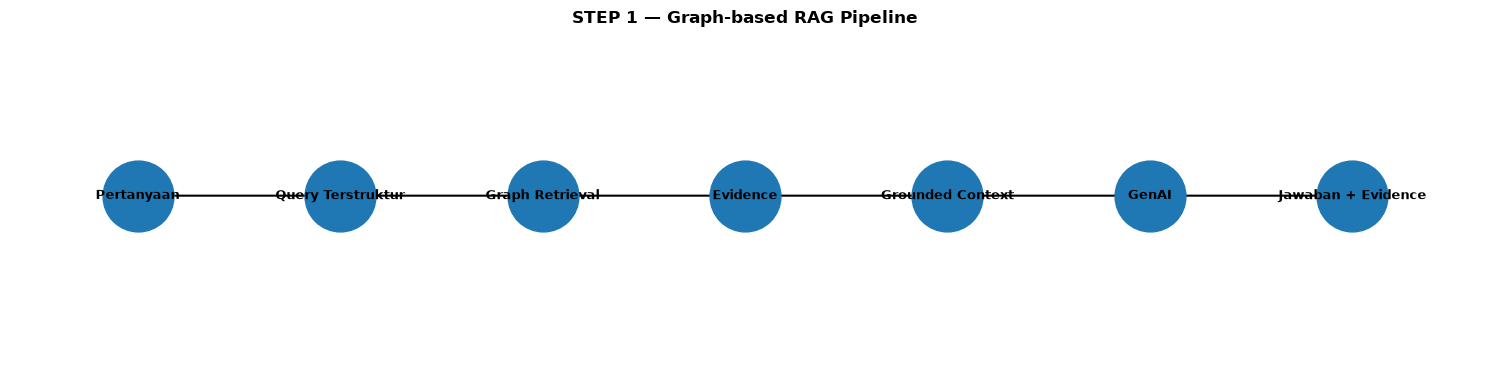

In [12]:
# ==============================================================
# 7.2 — VISUALISASI PIPELINE GRAPH RAG
# ==============================================================

import matplotlib.pyplot as plt

RAG = nx.DiGraph()

nodes = [
    "Pertanyaan",
    "Query Terstruktur",
    "Graph Retrieval",
    "Evidence",
    "Grounded Context",
    "GenAI",
    "Jawaban + Evidence",
]

for a, b in zip(nodes[:-1], nodes[1:]):
    RAG.add_edge(a, b)

pos = {n: (i, 0) for i, n in enumerate(nodes)}

fig, ax = plt.subplots(figsize=(15, 3.8))
nx.draw_networkx_nodes(RAG, pos, ax=ax, node_size=2600)
nx.draw_networkx_edges(
    RAG, pos, ax=ax, arrows=True, arrowsize=18, width=1.5
)
nx.draw_networkx_labels(
    RAG, pos, ax=ax, font_size=9, font_weight="bold"
)

ax.set_title(
    "STEP 1 — Graph-based RAG Pipeline",
    fontsize=12,
    fontweight="bold"
)
ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Evaluasi Grounding

Evaluasi awal tidak hanya melihat apakah jawaban terdengar benar, tetapi apakah jawaban memiliki dukungan evidence.

Indikator yang disiapkan:

1. **Evidence availability** — apakah graph memiliki fakta yang dibutuhkan.
2. **Traceability** — apakah fakta memiliki node dan relationship yang dapat ditelusuri.
3. **Numerical consistency** — apakah angka pada jawaban sesuai dengan evidence.
4. **Unsupported claim** — apakah terdapat klaim yang tidak ditemukan pada evidence.

Evaluasi otomatis penuh terhadap teks jawaban akan dilakukan setelah model GenAI dipasang.

In [13]:
# ==============================================================
# 8.1 — EVIDENCE SUMMARY
# ==============================================================

def evidence_summary(evidence):
    return pd.DataFrame([{
        "profile_evidence": len(evidence["profile_evidence"]),
        "innovation_evidence": len(evidence["innovation_evidence"]),
        "traversal_paths": len(evidence["paths"]),
        "grounding_available": (
            bool(evidence["profile_evidence"]) or
            bool(evidence["innovation_evidence"])
        )
    }])

display(evidence_summary(demo_evidence))

,profile_evidence,innovation_evidence,traversal_paths,grounding_available
0,9,20,20,True


# STEP 1 CHECKPOINT — GRAPH-BASED RAG

Pada tahap ini telah disiapkan:

- pembacaan Knowledge Graph hasil notebook sebelumnya;
- struktur query terarah;
- Graph Retrieval;
- pengambilan weighted profile evidence;
- pengambilan innovation evidence;
- traversal path;
- grounded context;
- grounded prompt;
- pemeriksaan ketersediaan evidence;
- visualisasi pipeline Graph-based RAG.

Tahap berikutnya dapat menambahkan koneksi GenAI untuk mengubah grounded context menjadi jawaban natural language.

Prinsip utama sistem:

> **Graph menjadi sumber evidence, retrieval menentukan konteks yang relevan, dan GenAI hanya menyusun jawaban berdasarkan konteks tersebut.**

# STEP 2 — GenAI Answer Generation dan Grounding

STEP 1 telah menyiapkan Graph Retrieval, evidence, traversal path, grounded context, dan grounded prompt.

STEP 2 menghubungkan context tersebut dengan model GenAI. Tujuannya bukan sekadar menghasilkan jawaban, tetapi memastikan jawaban **berdasarkan evidence yang berasal dari Knowledge Graph**.

Alur:

**Pertanyaan → Retrieval → Evidence → Grounded Context → GenAI → Jawaban + Evidence**

Model tidak digunakan untuk mencari data baru. Data faktual berasal dari Knowledge Graph.

## 2.1 Prinsip Grounded Generation

Jawaban dibentuk dengan tiga aturan utama:

1. Informasi faktual harus berasal dari evidence.
2. Angka dan nama entitas harus mengikuti evidence.
3. Jika evidence tidak cukup, jawaban harus menyatakan keterbatasan evidence.

Dengan prinsip ini, GenAI berfungsi sebagai **penyusun jawaban natural language**, sedangkan Knowledge Graph menjadi sumber fakta.

In [14]:
# ==============================================================
# 2.2 — KONFIGURASI GENAI
# ==============================================================

import os
import json
import pandas as pd

MODEL_NAME = os.getenv("OPENAI_MODEL", "gpt-6-luna")
OPENAI_API_KEY_AVAILABLE = bool(os.getenv("OPENAI_API_KEY"))

print("Model:", MODEL_NAME)
print("OPENAI_API_KEY tersedia:", OPENAI_API_KEY_AVAILABLE)

if not OPENAI_API_KEY_AVAILABLE:
    print(
        "API key belum tersedia. Retrieval dan grounded context "
        "tetap dapat diuji tanpa memanggil GenAI."
    )

Model: gpt-6-luna
OPENAI_API_KEY tersedia: False
API key belum tersedia. Retrieval dan grounded context tetap dapat diuji tanpa memanggil GenAI.


## 2.3 Koneksi ke OpenAI Responses API

Koneksi dibuat menggunakan Responses API. API key dibaca dari environment variable sehingga tidak ditulis langsung di notebook.

Model dapat diganti melalui `OPENAI_MODEL`. Pengujian awal cukup dilakukan pada beberapa pertanyaan agar penggunaan API tetap terkendali.

In [15]:
# ==============================================================
# 2.4 — CLIENT GENAI
# ==============================================================

genai_client = None

if OPENAI_API_KEY_AVAILABLE:
    try:
        from openai import OpenAI
        genai_client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])
        print("OpenAI client siap.")
    except ImportError:
        print(
            "Package openai belum tersedia. Instal package tersebut "
            "sebelum menjalankan pemanggilan GenAI."
        )
else:
    print("Client GenAI belum dibuat karena API key belum tersedia.")

Client GenAI belum dibuat karena API key belum tersedia.


In [16]:
# ==============================================================
# 2.5 — PROMPT GROUNDED GENERATION
# ==============================================================

GROUNDING_SYSTEM_PROMPT = (
    "Sistem ini adalah Graph-based RAG untuk data inovasi daerah.\n\n"
    "Tugas:\n"
    "- Jawab berdasarkan GRAPH EVIDENCE yang diberikan.\n"
    "- Jangan menambahkan fakta yang tidak terdapat pada evidence.\n"
    "- Jangan mengarang angka, nama daerah, nama inovasi, OPD, atau hubungan.\n"
    "- Pertahankan angka dan persentase sesuai evidence.\n"
    "- Jika evidence tidak cukup, nyatakan dengan jelas bahwa evidence "
    "pada Knowledge Graph tidak cukup.\n"
    "- Bedakan fakta individual dengan karakteristik agregatif berbobot.\n"
    "- Jangan menganggap weight sebagai skor kualitas atau peringkat.\n"
    "- Setelah jawaban, tampilkan bagian 'Evidence yang digunakan'."
)

def build_genai_input(question, grounded_context):
    return (
        "PERTANYAAN:\n" + question +
        "\n\nGRAPH EVIDENCE:\n" + grounded_context
    )

print(GROUNDING_SYSTEM_PROMPT)

Sistem ini adalah Graph-based RAG untuk data inovasi daerah.

Tugas:
- Jawab berdasarkan GRAPH EVIDENCE yang diberikan.
- Jangan menambahkan fakta yang tidak terdapat pada evidence.
- Jangan mengarang angka, nama daerah, nama inovasi, OPD, atau hubungan.
- Pertahankan angka dan persentase sesuai evidence.
- Jika evidence tidak cukup, nyatakan dengan jelas bahwa evidence pada Knowledge Graph tidak cukup.
- Bedakan fakta individual dengan karakteristik agregatif berbobot.
- Jangan menganggap weight sebagai skor kualitas atau peringkat.
- Setelah jawaban, tampilkan bagian 'Evidence yang digunakan'.


## 2.6 Pemanggilan GenAI

Fungsi berikut mengirim pertanyaan dan grounded context ke model. Context yang dikirim berasal dari retrieval sebelumnya.

Jika API key belum tersedia, fungsi tidak melakukan pemanggilan API.

In [17]:
# ==============================================================
# 2.7 — GENERATE GROUNDED ANSWER
# ==============================================================

def generate_grounded_answer(question, grounded_context, model=None):
    if model is None:
        model = MODEL_NAME

    if genai_client is None:
        return {
            "status": "not_executed",
            "answer": None,
            "reason": "OPENAI_API_KEY belum tersedia atau client belum siap.",
            "question": question,
        }

    response = genai_client.responses.create(
        model=model,
        instructions=GROUNDING_SYSTEM_PROMPT,
        input=build_genai_input(question, grounded_context),
    )

    return {
        "status": "success",
        "answer": response.output_text,
        "question": question,
        "model": model,
        "response_id": response.id,
    }

print("Fungsi generate_grounded_answer siap.")

Fungsi generate_grounded_answer siap.


## 2.8 Contoh Pertanyaan — Karakteristik Profil

Pertanyaan pertama menguji kemampuan model menyusun ringkasan dari weighted evidence.

Retrieval:

`Profil → weighted Jenis / Urusan / Tahapan / Bentuk`

GenAI hanya menyusun informasi tersebut menjadi jawaban yang mudah dibaca.

In [18]:
# ==============================================================
# 2.9 — QA TEST A: PROFILE CHARACTERISTICS
# ==============================================================

question_A = "Apa karakteristik profil ekosistem inovasi yang ditampilkan?"

result_A = generate_grounded_answer(
    question_A,
    grounded_context
)

print("Status:", result_A["status"])

if result_A["answer"]:
    print("\n=== JAWABAN GENAI ===\n")
    print(result_A["answer"])
else:
    print("Jawaban belum dibuat karena client GenAI belum tersedia.")

Status: not_executed
Jawaban belum dibuat karena client GenAI belum tersedia.


## 2.10 Contoh Pertanyaan — Inovasi Berdasarkan Kriteria

Pertanyaan kedua menguji retrieval multi-hop.

Jalur:

`Profil → Daerah → Inovasi → Jenis + Urusan`

Evidence hasil traversal kemudian menjadi context untuk GenAI.

In [19]:
# ==============================================================
# 2.11 — QA TEST B: MULTI-HOP INNOVATION
# ==============================================================

if demo_profile:
    multi_hop_results = retrieve_innovations_basic(
        profil_id=demo_profile,
        jenis="Digital",
        urusan="pendidikan",
        limit=20
    )

    multi_hop_evidence = build_graph_evidence(
        profile_id=demo_profile,
        jenis="Digital",
        urusan="pendidikan",
        limit=20
    )

    multi_hop_context = build_grounded_context(multi_hop_evidence)

    question_B = (
        "Apa saja inovasi Digital pada urusan pendidikan "
        "yang ditemukan dalam profil tersebut?"
    )

    result_B = generate_grounded_answer(
        question_B,
        multi_hop_context
    )

    print("Jumlah hasil retrieval:", len(multi_hop_results))
    print("Status GenAI:", result_B["status"])

    if result_B["answer"]:
        print("\n=== JAWABAN GENAI ===\n")
        print(result_B["answer"])
else:
    print("Profil demo tidak tersedia.")

Jumlah hasil retrieval: 5
Status GenAI: not_executed


## 2.12 Evidence Citation

Jawaban disertai daftar evidence yang menjadi dasar jawaban.

Penanda evidence membantu proses pemeriksaan dan membuat jawaban dapat ditelusuri kembali ke graph.

In [20]:
# ==============================================================
# 2.13 — EVIDENCE INDEX
# ==============================================================

def index_evidence(evidence):
    indexed = []

    for i, item in enumerate(evidence.get("profile_evidence", []), start=1):
        indexed.append({
            "evidence_id": f"E{i}",
            "type": "profile",
            "source": item.get("source"),
            "relationship": item.get("relationship"),
            "target": item.get("target"),
            "weight": item.get("weight"),
            "percentage": item.get("percentage"),
            "count": item.get("count"),
            "total": item.get("total"),
        })

    start = len(indexed) + 1

    for j, item in enumerate(
        evidence.get("innovation_evidence", []),
        start=start
    ):
        indexed.append({
            "evidence_id": f"E{j}",
            "type": "innovation",
            "source": item.get("inovasi_id"),
            "relationship": "innovation_evidence",
            "target": item.get("judul"),
            "weight": None,
            "percentage": None,
            "count": None,
            "total": None,
        })

    return pd.DataFrame(indexed)

evidence_index_A = index_evidence(demo_evidence)
display(evidence_index_A.head(30))

,evidence_id,type,source,relationship,target,weight,percentage,count,total
0,E1,profile,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,Teknologi,0.46,46.0,23.0,50.0
1,E2,profile,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,Non Digital,0.40,40.0,20.0,50.0
2,E3,profile,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,Digital,0.14,14.0,7.0,50.0
3,E4,profile,Profil Ekosistem Wilayah 1,DOMINAN_URUSAN,kesehatan,0.66,66.0,33.0,50.0
4,E5,profile,Profil Ekosistem Wilayah 1,DOMINAN_URUSAN,pendidikan,0.34,34.0,17.0,50.0
5,E6,profile,Profil Ekosistem Wilayah 1,DOMINAN_TAHAPAN,Penerapan,1.00,100.0,50.0,50.0
6,E7,profile,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,Inovasi pelayanan publik,0.90,90.0,45.0,50.0
7,E8,profile,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,Inovasi Daerah lainnya sesuai dengan Urusan Pe...,0.06,6.0,3.0,50.0
8,E9,profile,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,Inovasi tata kelola pemerintahan daerah,0.04,4.0,2.0,50.0
9,E10,innovation,INV_0031,innovation_evidence,SAMPAH MART SOLUSI EKOLOGI DAN EKONOMI MASA KINI,NaN,NaN,NaN,NaN


## 2.14 Grounding Check

Pemeriksaan awal memastikan jawaban memiliki evidence. Pemeriksaan ini belum mengklaim bahwa seluruh klaim bahasa natural pasti benar; evaluasi klaim yang lebih mendalam dilakukan pada tahap evaluasi.

In [21]:
# ==============================================================
# 2.15 — BASIC GROUNDING CHECK
# ==============================================================

def basic_grounding_check(result, evidence):
    evidence_count = (
        len(evidence.get("profile_evidence", [])) +
        len(evidence.get("innovation_evidence", []))
    )

    return {
        "answer_generated": result.get("status") == "success",
        "evidence_available": evidence_count > 0,
        "evidence_count": evidence_count,
        "traversal_path_available": bool(evidence.get("paths")),
        "grounding_input_available": evidence_count > 0,
    }

grounding_A = basic_grounding_check(result_A, demo_evidence)
display(pd.DataFrame([grounding_A]))

,answer_generated,evidence_available,evidence_count,traversal_path_available,grounding_input_available
0,False,True,29,True,True


## 2.16 Visualisasi Alur Jawaban

Visualisasi menunjukkan posisi GenAI setelah retrieval. Model menerima context yang telah diperoleh dari Knowledge Graph.

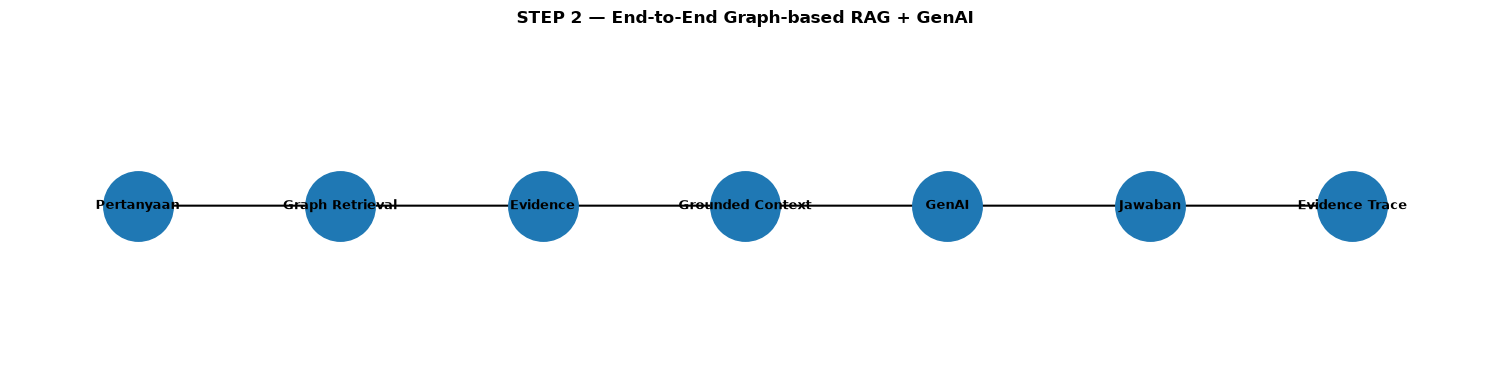

In [22]:
# ==============================================================
# 2.17 — VISUALISASI END-TO-END
# ==============================================================

R_end = nx.DiGraph()

pipeline = [
    "Pertanyaan",
    "Graph Retrieval",
    "Evidence",
    "Grounded Context",
    "GenAI",
    "Jawaban",
    "Evidence Trace"
]

for a, b in zip(pipeline[:-1], pipeline[1:]):
    R_end.add_edge(a, b)

pos = {n: (i, 0) for i, n in enumerate(pipeline)}

fig, ax = plt.subplots(figsize=(15, 4))
nx.draw_networkx_nodes(R_end, pos, ax=ax, node_size=2500)
nx.draw_networkx_edges(
    R_end, pos, ax=ax, arrows=True, arrowsize=18, width=1.5
)
nx.draw_networkx_labels(
    R_end, pos, ax=ax, font_size=9, font_weight="bold"
)

ax.set_title(
    "STEP 2 — End-to-End Graph-based RAG + GenAI",
    fontsize=12,
    fontweight="bold"
)
ax.axis("off")
plt.tight_layout()
plt.show()

## 2.18 Catatan Implementasi

Koneksi GenAI menggunakan Responses API. API key tidak disimpan di notebook.

Pada tahap pengembangan, retrieval dan grounded context dapat diuji terlebih dahulu tanpa API. Setelah context dinyatakan benar, pemanggilan GenAI dilakukan pada sejumlah pertanyaan uji.

Sumber implementasi API: dokumentasi resmi OpenAI mengenai Responses API. citeturn0search0

# STEP 2 CHECKPOINT — GRAPH-BASED RAG + GENAI

Tahap ini menghubungkan hasil Graph Retrieval dengan GenAI.

Hasil utama:

- grounded generation prompt;
- koneksi GenAI;
- jawaban berdasarkan Graph Evidence;
- multi-hop retrieval sebagai sumber context;
- evidence index;
- basic grounding check;
- visualisasi alur end-to-end.

Prinsip sistem:

> **Knowledge Graph menyediakan fakta, Graph Retrieval memilih evidence yang relevan, dan GenAI menyusun evidence tersebut menjadi jawaban natural language.**

Jika evidence tidak tersedia, sistem tidak seharusnya membuat fakta baru.

# STEP 3 — Evaluasi Graph-based RAG

Tahap ini mengevaluasi apakah jawaban GenAI benar-benar didukung oleh evidence yang diambil dari Knowledge Graph.

Evaluasi tidak hanya melihat apakah jawaban terdengar baik. Fokusnya adalah:

- apakah evidence tersedia;
- apakah fakta pada jawaban sesuai dengan evidence;
- apakah angka dan persentase tetap konsisten;
- apakah jalur graph dapat ditelusuri;
- apakah sistem menolak menjawab ketika evidence tidak cukup.

Alur evaluasi:

**Question → Retrieval → Evidence → GenAI Answer → Grounding Evaluation**

## 3.1 Mengapa Evaluasi Diperlukan?

Graph-based RAG memiliki dua bagian yang perlu diuji secara terpisah:

1. **Retrieval** — apakah graph mengambil evidence yang benar?
2. **Generation** — apakah GenAI menyusun jawaban tanpa menambahkan fakta yang tidak didukung?

Dengan pemisahan ini, jika terjadi kesalahan dapat diketahui apakah sumbernya berasal dari retrieval atau dari proses generasi.

In [23]:
# ==============================================================
# 3.2 — PREPARE EVALUATION UTILITIES
# ==============================================================

import re
import math
import pandas as pd
import numpy as np

print("Evaluation utilities siap.")

Evaluation utilities siap.


## 3.3 Dataset Pertanyaan Evaluasi

Pertanyaan dibuat dari pola query yang memang didukung oleh Knowledge Graph.

Kategori:

- pertanyaan profil;
- pertanyaan multi-hop;
- pertanyaan faktual inovasi;
- pertanyaan dengan angka/weighted characteristics;
- pertanyaan yang seharusnya tidak dapat dijawab karena evidence tidak tersedia.

Nilai entity diambil dari graph, bukan dibuat secara manual.

In [24]:
# ==============================================================
# 3.4 — BUILD EVALUATION QUESTIONS FROM GRAPH
# ==============================================================

def first_node_of_type(node_type):
    for n, d in G.nodes(data=True):
        if d.get("type") == node_type:
            return n
    return None

eval_profile = demo_profile if "demo_profile" in globals() else first_node_of_type(
    "ProfilEkosistemInovasi"
)

eval_questions = []

if eval_profile:
    eval_questions.append({
        "question_id": "E01",
        "category": "profile",
        "question": f"Apa karakteristik {_g_name(eval_profile)}?",
        "profil_id": eval_profile,
        "jenis": None,
        "urusan": None,
    })

eval_questions.extend([
    {
        "question_id": "E02",
        "category": "multi_hop",
        "question": "Apa saja inovasi Digital pada urusan pendidikan dalam profil tersebut?",
        "profil_id": eval_profile,
        "jenis": "Digital",
        "urusan": "pendidikan",
    },
    {
        "question_id": "E03",
        "category": "profile_weight",
        "question": "Berapa persentase karakteristik berbobot pada profil tersebut?",
        "profil_id": eval_profile,
        "jenis": None,
        "urusan": None,
    },
    {
        "question_id": "E04",
        "category": "unsupported",
        "question": "Berapa anggaran tahunan inovasi pada profil tersebut?",
        "profil_id": eval_profile,
        "jenis": None,
        "urusan": None,
    },
])

evaluation_questions = pd.DataFrame(eval_questions)
display(evaluation_questions)

,question_id,category,question,profil_id,jenis,urusan
0,E01,profile,Apa karakteristik Profil Ekosistem Wilayah 1?,PROFILE_EKO_01,NaN,NaN
1,E02,multi_hop,Apa saja inovasi Digital pada urusan pendidika...,PROFILE_EKO_01,Digital,pendidikan
2,E03,profile_weight,Berapa persentase karakteristik berbobot pada ...,PROFILE_EKO_01,NaN,NaN
3,E04,unsupported,Berapa anggaran tahunan inovasi pada profil te...,PROFILE_EKO_01,NaN,NaN


## 3.5 Fungsi Evaluasi Retrieval

Setiap pertanyaan menghasilkan:

- jumlah evidence;
- jumlah innovation evidence;
- jumlah profile evidence;
- jumlah traversal path;
- status apakah retrieval memiliki dasar untuk menjawab.

Pertanyaan unsupported digunakan untuk menguji apakah sistem mengenali bahwa informasi tertentu memang tidak terdapat pada graph.

In [25]:
# ==============================================================
# 3.6 — RETRIEVAL EVALUATION
# ==============================================================

def evaluate_retrieval_case(row):
    evidence = build_graph_evidence(
        profile_id=row["profil_id"],
        jenis=row["jenis"],
        urusan=row["urusan"],
        limit=20
    )

    profile_count = len(evidence["profile_evidence"])
    innovation_count = len(evidence["innovation_evidence"])
    path_count = len(evidence["paths"])

    return {
        "question_id": row["question_id"],
        "category": row["category"],
        "profile_evidence": profile_count,
        "innovation_evidence": innovation_count,
        "paths": path_count,
        "evidence_available": (
            profile_count + innovation_count > 0
        ),
        "retrieval_status": (
            "SUPPORTED" if profile_count + innovation_count > 0
            else "NO_EVIDENCE"
        )
    }

retrieval_eval = pd.DataFrame([
    evaluate_retrieval_case(row)
    for _, row in evaluation_questions.iterrows()
])

display(retrieval_eval)

,question_id,category,profile_evidence,innovation_evidence,paths,evidence_available,retrieval_status
0,E01,profile,9,0,0,True,SUPPORTED
1,E02,multi_hop,9,5,5,True,SUPPORTED
2,E03,profile_weight,9,0,0,True,SUPPORTED
3,E04,unsupported,9,0,0,True,SUPPORTED


## 3.7 Evaluasi Konsistensi Angka

Untuk evidence berbobot, angka penting seperti percentage dan count harus dipertahankan.

Pemeriksaan dilakukan langsung terhadap nilai pada graph. Ini membantu mencegah perubahan angka ketika evidence disusun menjadi context.

In [26]:
# ==============================================================
# 3.8 — NUMERICAL EVIDENCE CHECK
# ==============================================================

def numerical_evidence_check(profile_id):
    df = graph_weighted_profile(profile_id)

    if df.empty:
        return pd.DataFrame()

    rows = []
    for _, r in df.iterrows():
        pct = float(r["percentage"])
        weight = float(r["weight"])

        rows.append({
            "profil": r["profil"],
            "relationship": r["relationship"],
            "target": r["target"],
            "percentage": pct,
            "weight": weight,
            "percentage_valid": 0 <= pct <= 100,
            "weight_valid": 0 <= weight <= 1,
            "consistent": math.isclose(
                pct / 100.0,
                weight,
                rel_tol=1e-6,
                abs_tol=1e-6
            )
        })

    return pd.DataFrame(rows)

numerical_check = (
    numerical_evidence_check(eval_profile)
    if eval_profile else pd.DataFrame()
)

display(numerical_check)

,profil,relationship,target,percentage,weight,percentage_valid,weight_valid,consistent
0,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,Teknologi,46.0,0.46,True,True,True
1,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,Non Digital,40.0,0.40,True,True,True
2,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,Digital,14.0,0.14,True,True,True
3,Profil Ekosistem Wilayah 1,DOMINAN_URUSAN,kesehatan,66.0,0.66,True,True,True
4,Profil Ekosistem Wilayah 1,DOMINAN_URUSAN,pendidikan,34.0,0.34,True,True,True
5,Profil Ekosistem Wilayah 1,DOMINAN_TAHAPAN,Penerapan,100.0,1.00,True,True,True
6,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,Inovasi pelayanan publik,90.0,0.90,True,True,True
7,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,Inovasi Daerah lainnya sesuai dengan Urusan Pe...,6.0,0.06,True,True,True
8,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,Inovasi tata kelola pemerintahan daerah,4.0,0.04,True,True,True


## 3.9 Grounding Rule untuk Jawaban

Jawaban dianggap grounded apabila klaim faktualnya dapat ditemukan pada evidence.

Pemeriksaan sederhana dilakukan dengan mencocokkan:

- nama entity;
- angka;
- persentase;
- relationship penting.

Pemeriksaan ini merupakan **screening awal**, bukan pengganti evaluasi manual oleh evaluator.

In [27]:
# ==============================================================
# 3.10 — CLAIM / EVIDENCE SCREENING
# ==============================================================

def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def extract_numbers(text):
    return re.findall(r"(?<![A-Za-z])\d+(?:[.,]\d+)?", str(text))

def evidence_text(evidence):
    parts = []

    for e in evidence.get("profile_evidence", []):
        parts.extend([
            str(e.get("source", "")),
            str(e.get("relationship", "")),
            str(e.get("target", "")),
            str(e.get("percentage", "")),
            str(e.get("count", "")),
            str(e.get("total", "")),
        ])

    for e in evidence.get("innovation_evidence", []):
        parts.extend([
            str(e.get("inovasi_id", "")),
            str(e.get("judul", "")),
            str(e.get("daerah", "")),
            str(e.get("opd", "")),
            str(e.get("jenis", "")),
            str(e.get("urusan", "")),
            str(e.get("tahapan", "")),
            str(e.get("kematangan", "")),
        ])

    return normalize_text(" ".join(parts))

def grounding_screen(answer, evidence):
    if not answer:
        return {
            "answer_available": False,
            "numeric_claims": 0,
            "numeric_claims_found": 0,
            "numeric_coverage": 0.0,
            "status": "NO_ANSWER"
        }

    ans = normalize_text(answer)
    ev = evidence_text(evidence)

    nums = extract_numbers(answer)
    found = sum(
        1 for x in nums
        if normalize_text(x) in ev
    )

    coverage = found / len(nums) if nums else 1.0

    return {
        "answer_available": True,
        "numeric_claims": len(nums),
        "numeric_claims_found": found,
        "numeric_coverage": coverage,
        "status": (
            "NUMERIC_SUPPORTED"
            if coverage >= 1.0
            else "CHECK_REQUIRED"
        )
    }

print("Grounding screening siap.")

Grounding screening siap.


## 3.11 Jalankan Evaluasi GenAI

Jika API key tersedia, pertanyaan evaluasi dikirim ke GenAI menggunakan context hasil retrieval.

Jika API key belum tersedia, retrieval tetap dievaluasi dan kolom jawaban GenAI dibiarkan kosong.

In [28]:
# ==============================================================
# 3.12 — RUN EVALUATION CASES
# ==============================================================

evaluation_outputs = []

for _, row in evaluation_questions.iterrows():
    evidence = build_graph_evidence(
        profile_id=row["profil_id"],
        jenis=row["jenis"],
        urusan=row["urusan"],
        limit=20
    )

    context = build_grounded_context(
        evidence
    )

    result = generate_grounded_answer(
        row["question"],
        context
    )

    screen = grounding_screen(
        result.get("answer"),
        evidence
    )

    evaluation_outputs.append({
        "question_id": row["question_id"],
        "category": row["category"],
        "question": row["question"],
        "genai_status": result.get("status"),
        "answer": result.get("answer"),
        "evidence_count": (
            len(evidence["profile_evidence"]) +
            len(evidence["innovation_evidence"])
        ),
        "path_count": len(evidence["paths"]),
        "numeric_coverage": screen["numeric_coverage"],
        "grounding_status": screen["status"],
    })

evaluation_results = pd.DataFrame(evaluation_outputs)
display(
    evaluation_results[
        [
            "question_id",
            "category",
            "genai_status",
            "evidence_count",
            "path_count",
            "numeric_coverage",
            "grounding_status",
        ]
    ]
)

,question_id,category,genai_status,evidence_count,path_count,numeric_coverage,grounding_status
0,E01,profile,not_executed,9,0,0.0,NO_ANSWER
1,E02,multi_hop,not_executed,14,5,0.0,NO_ANSWER
2,E03,profile_weight,not_executed,9,0,0.0,NO_ANSWER
3,E04,unsupported,not_executed,9,0,0.0,NO_ANSWER


## 3.13 Evaluasi Pertanyaan Unsupported

Pertanyaan tentang informasi yang tidak terdapat pada graph harus menghasilkan salah satu dari dua kondisi:

- GenAI menyatakan evidence tidak cukup; atau
- sistem tidak memberikan jawaban faktual.

Hal ini penting untuk menguji kemampuan sistem menghindari hallucination.

In [29]:
# ==============================================================
# 3.14 — UNSUPPORTED QUERY CHECK
# ==============================================================

unsupported = evaluation_results[
    evaluation_results["category"] == "unsupported"
].copy()

if not unsupported.empty:
    print("=== UNSUPPORTED QUERY ===")
    display(
        unsupported[
            [
                "question_id",
                "question",
                "genai_status",
                "evidence_count",
                "grounding_status"
            ]
        ]
    )

    print(
        "\nAturan: apabila evidence_count = 0, jawaban idealnya "
        "menyatakan bahwa evidence tidak tersedia."
    )
else:
    print("Tidak ada unsupported query.")

=== UNSUPPORTED QUERY ===


,question_id,question,genai_status,evidence_count,grounding_status
3,E04,Berapa anggaran tahunan inovasi pada profil te...,not_executed,9,NO_ANSWER



Aturan: apabila evidence_count = 0, jawaban idealnya menyatakan bahwa evidence tidak tersedia.


## 3.15 Visualisasi Hasil Evaluasi

Visualisasi berikut memperlihatkan jumlah evidence yang tersedia untuk setiap pertanyaan.

Tujuannya bukan memberi skor kualitas secara langsung, tetapi memperlihatkan apakah pertanyaan memiliki dasar informasi yang dapat digunakan Graph RAG.

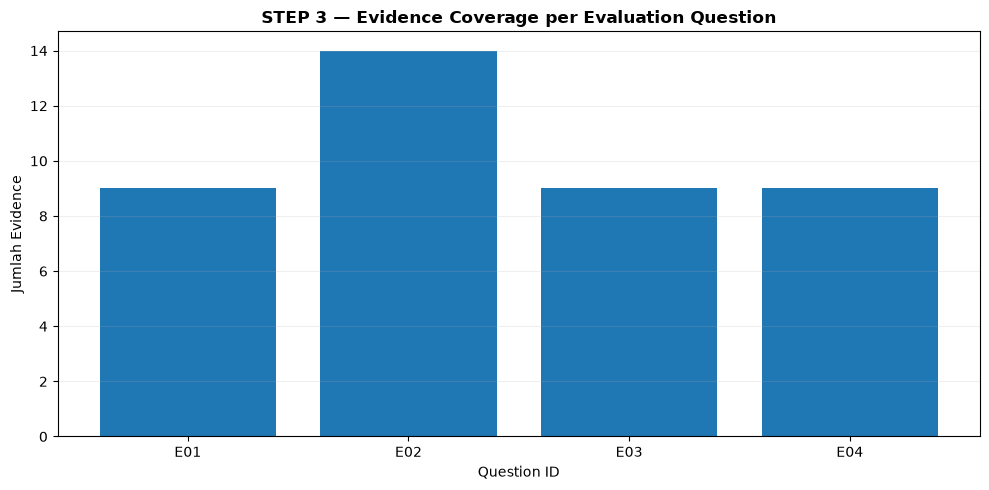

In [30]:
# ==============================================================
# 3.16 — VISUALISASI EVIDENCE COVERAGE
# ==============================================================

plot_df = retrieval_eval.copy()

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    plot_df["question_id"],
    plot_df["profile_evidence"] + plot_df["innovation_evidence"]
)

ax.set_title(
    "STEP 3 — Evidence Coverage per Evaluation Question",
    fontsize=12,
    fontweight="bold"
)
ax.set_xlabel("Question ID")
ax.set_ylabel("Jumlah Evidence")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

## 3.17 Ringkasan Evaluasi

Evaluasi dipisahkan menjadi:

**Retrieval correctness**
- apakah evidence ditemukan;
- apakah traversal path tersedia.

**Generation grounding**
- apakah jawaban memiliki evidence;
- apakah angka pada jawaban didukung evidence.

**Abstention**
- apakah sistem tidak mengarang ketika evidence tidak tersedia.

Evaluasi manual tetap diperlukan untuk menilai kualitas bahasa, kelengkapan jawaban, dan ketepatan makna.

In [31]:
# ==============================================================
# 3.18 — CHECKPOINT TABLE
# ==============================================================

checkpoint_step3 = pd.DataFrame([{
    "total_questions": len(evaluation_results),
    "supported_retrieval": int(
        (retrieval_eval["retrieval_status"] == "SUPPORTED").sum()
    ),
    "no_evidence": int(
        (retrieval_eval["retrieval_status"] == "NO_EVIDENCE").sum()
    ),
    "genai_success": int(
        (evaluation_results["genai_status"] == "success").sum()
    ),
    "numeric_grounding_full": int(
        (evaluation_results["numeric_coverage"] >= 1.0).sum()
    ),
}])

display(checkpoint_step3)

,total_questions,supported_retrieval,no_evidence,genai_success,numeric_grounding_full
0,4,4,0,0,0


# STEP 3 CHECKPOINT — EVALUASI GRAPH-BASED RAG

Evaluasi telah mencakup:

1. evaluasi retrieval;
2. ketersediaan evidence;
3. validasi angka dan persentase;
4. screening grounding jawaban;
5. pengujian pertanyaan unsupported;
6. visualisasi evidence coverage;
7. ringkasan hasil evaluasi.

Kesimpulan tahap:

> **Graph-based RAG tidak hanya dinilai dari kemampuan menghasilkan jawaban, tetapi dari kemampuan mengambil evidence yang benar dan menjaga jawaban tetap sesuai dengan evidence tersebut.**

Tahap selanjutnya dapat difokuskan pada penyempurnaan evaluasi, antarmuka tanya jawab, atau deployment setelah hasil evaluasi dinyatakan memadai.

# STEP 4 — End-to-End Graph-based RAG Pipeline

Tahap ini menggabungkan komponen STEP 1–3 menjadi satu alur penggunaan. Fokusnya adalah membuat pipeline yang menerima pertanyaan, mengambil evidence dari Knowledge Graph, menyusun grounded context, lalu menghasilkan jawaban GenAI beserta provenance.

**Question → Retrieval → Evidence → Grounded Context → GenAI → Answer + Provenance**

Knowledge Graph tidak dibangun ulang pada tahap ini.

## 4.1 Konsep Sistem Akhir

Sistem terdiri dari empat lapisan:

- **Data Layer:** Knowledge Graph berisi entity, relationship faktual, dan weighted relationship.
- **Retrieval Layer:** graph traversal mengambil fakta yang relevan.
- **Generation Layer:** grounded context diberikan kepada GenAI.
- **Evidence Layer:** provenance menjaga keterlacakan jawaban ke graph.

Tujuannya adalah menunjukkan bahwa GenAI berperan menyusun jawaban, sedangkan sumber faktanya tetap berasal dari Knowledge Graph.

In [32]:
# ==============================================================
# 4.2 — END-TO-END GRAPH RAG FUNCTION
# ==============================================================

def ask_graph_rag(question, profil_id=None, jenis=None, urusan=None, limit=20):
    evidence = build_graph_evidence(
        profile_id=profil_id,
        jenis=jenis,
        urusan=urusan,
        limit=limit
    )

    context = build_grounded_context(evidence)

    genai_result = generate_grounded_answer(
        question,
        context
    )

    return {
        "question": question,
        "retrieval": {
            "profile_id": profil_id,
            "jenis": jenis,
            "urusan": urusan,
            "limit": limit
        },
        "evidence": evidence,
        "grounded_context": context,
        "answer": genai_result
    }

print("Pipeline end-to-end Graph RAG siap.")

Pipeline end-to-end Graph RAG siap.


## 4.3 Skenario Utama — Pertanyaan Profil

Skenario pertama menjawab pertanyaan tentang karakteristik profil ekosistem inovasi. Evidence utama berasal dari weighted relationship pada profil.

In [33]:
# ==============================================================
# 4.4 — DEMO A: PROFILE QUESTION
# ==============================================================

question_demo_A = (
    f"Apa karakteristik {_g_name(eval_profile)} "
    "berdasarkan data Knowledge Graph?"
)

demo_A = ask_graph_rag(
    question=question_demo_A,
    profil_id=eval_profile,
    limit=20
)

print("QUESTION:")
print(demo_A["question"])

print("\nRETRIEVAL:")
print(demo_A["retrieval"])

print("\nEVIDENCE:")
print(
    "Profile:", len(demo_A["evidence"]["profile_evidence"]),
    "| Innovation:", len(demo_A["evidence"]["innovation_evidence"]),
    "| Paths:", len(demo_A["evidence"]["paths"])
)

print("\nGENAI STATUS:")
print(demo_A["answer"]["status"])

if demo_A["answer"].get("answer"):
    print("\nANSWER:\n")
    print(demo_A["answer"]["answer"])

QUESTION:
Apa karakteristik Profil Ekosistem Wilayah 1 berdasarkan data Knowledge Graph?

RETRIEVAL:
{'profile_id': 'PROFILE_EKO_01', 'jenis': None, 'urusan': None, 'limit': 20}

EVIDENCE:
Profile: 9 | Innovation: 20 | Paths: 20

GENAI STATUS:
not_executed


## 4.5 Skenario Multi-Hop

Skenario kedua menggunakan:

`Profil → Daerah → Inovasi → Jenis + Urusan`

Ini memperlihatkan fungsi Knowledge Graph yang tidak hanya berupa pencarian pada satu tabel.

In [34]:
# ==============================================================
# 4.6 — DEMO B: MULTI-HOP QUESTION
# ==============================================================

question_demo_B = (
    "Apa saja inovasi Digital pada urusan pendidikan "
    "yang ditemukan dalam profil tersebut?"
)

demo_B = ask_graph_rag(
    question=question_demo_B,
    profil_id=eval_profile,
    jenis="Digital",
    urusan="pendidikan",
    limit=20
)

print("QUESTION:")
print(demo_B["question"])

print("\nJUMLAH HASIL RETRIEVAL:")
print(len(demo_B["evidence"]["innovation_evidence"]))

if demo_B["answer"].get("answer"):
    print("\nANSWER:\n")
    print(demo_B["answer"]["answer"])
else:
    print("\nGenAI belum dipanggil atau tidak tersedia.")

QUESTION:
Apa saja inovasi Digital pada urusan pendidikan yang ditemukan dalam profil tersebut?

JUMLAH HASIL RETRIEVAL:
5

GenAI belum dipanggil atau tidak tersedia.


## 4.7 Provenance Jawaban

Provenance menunjukkan dari mana informasi jawaban berasal. Setiap hasil retrieval tetap menyimpan ID entity, relationship, target, nilai berbobot bila tersedia, dan jalur traversal.

In [35]:
# ==============================================================
# 4.8 — PROVENANCE TABLE
# ==============================================================

def provenance_table(evidence):
    rows = []

    for e in evidence.get("profile_evidence", []):
        rows.append({
            "evidence_id": f"E{len(rows)+1:03d}",
            "source": e.get("source"),
            "relationship": e.get("relationship"),
            "target": e.get("target"),
            "percentage": e.get("percentage"),
            "count": e.get("count"),
            "path": None
        })

    for e in evidence.get("innovation_evidence", []):
        rows.append({
            "evidence_id": f"E{len(rows)+1:03d}",
            "source": e.get("inovasi_id"),
            "relationship": "innovation_evidence",
            "target": e.get("judul"),
            "percentage": None,
            "count": None,
            "path": None
        })

    for path in evidence.get("paths", []):
        rows.append({
            "evidence_id": f"E{len(rows)+1:03d}",
            "source": "TRAVERSAL",
            "relationship": "PATH",
            "target": path,
            "percentage": None,
            "count": None,
            "path": path
        })

    return pd.DataFrame(rows)

provenance_A = provenance_table(demo_A["evidence"])
display(provenance_A.head(30))

,evidence_id,source,relationship,target,percentage,count,path
0,E001,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,Teknologi,46.0,23.0,NaN
1,E002,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,Non Digital,40.0,20.0,NaN
2,E003,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,Digital,14.0,7.0,NaN
3,E004,Profil Ekosistem Wilayah 1,DOMINAN_URUSAN,kesehatan,66.0,33.0,NaN
4,E005,Profil Ekosistem Wilayah 1,DOMINAN_URUSAN,pendidikan,34.0,17.0,NaN
5,E006,Profil Ekosistem Wilayah 1,DOMINAN_TAHAPAN,Penerapan,100.0,50.0,NaN
6,E007,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,Inovasi pelayanan publik,90.0,45.0,NaN
7,E008,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,Inovasi Daerah lainnya sesuai dengan Urusan Pe...,6.0,3.0,NaN
8,E009,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,Inovasi tata kelola pemerintahan daerah,4.0,2.0,NaN
9,E010,INV_0031,innovation_evidence,SAMPAH MART SOLUSI EKOLOGI DAN EKONOMI MASA KINI,NaN,NaN,NaN


## 4.9 Pemeriksaan Konsistensi End-to-End

Pemeriksaan dasar memastikan retrieval menghasilkan evidence, context tersedia, GenAI menerima context yang sama, dan provenance tetap tersedia setelah generation.

In [36]:
# ==============================================================
# 4.10 — END-TO-END CONSISTENCY CHECK
# ==============================================================

def end_to_end_check(result):
    evidence = result["evidence"]
    context = result["grounded_context"]
    answer = result["answer"]

    evidence_count = (
        len(evidence.get("profile_evidence", [])) +
        len(evidence.get("innovation_evidence", []))
    )

    return {
        "question_available": bool(result["question"]),
        "retrieval_executed": True,
        "evidence_count": evidence_count,
        "context_available": bool(context),
        "genai_executed": answer.get("status") == "success",
        "provenance_available": (
            len(evidence.get("paths", [])) > 0 or evidence_count > 0
        )
    }

e2e_check = end_to_end_check(demo_A)
display(pd.DataFrame([e2e_check]))

,question_available,retrieval_executed,evidence_count,context_available,genai_executed,provenance_available
0,True,True,29,True,False,True


## 4.11 Visualisasi Sistem End-to-End

Visualisasi ini menjadi gambaran utama pipeline yang dapat digunakan untuk menjelaskan sistem pada presentasi.

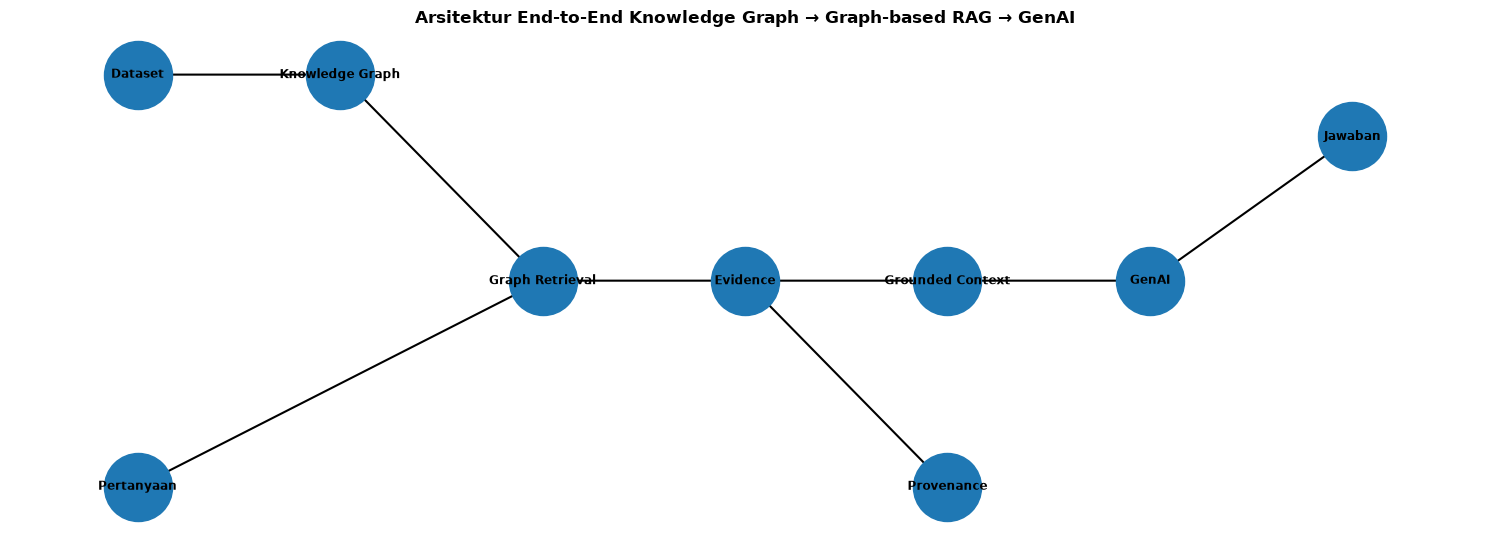

In [37]:
# ==============================================================
# 4.12 — VISUALISASI ARSITEKTUR GRAPH RAG
# ==============================================================

R_arch = nx.DiGraph()

arch_edges = [
    ("Dataset", "Knowledge Graph"),
    ("Knowledge Graph", "Graph Retrieval"),
    ("Pertanyaan", "Graph Retrieval"),
    ("Graph Retrieval", "Evidence"),
    ("Evidence", "Grounded Context"),
    ("Grounded Context", "GenAI"),
    ("GenAI", "Jawaban"),
    ("Evidence", "Provenance"),
]

R_arch.add_edges_from(arch_edges)

pos = {
    "Dataset": (0, 1),
    "Knowledge Graph": (2, 1),
    "Pertanyaan": (0, -1),
    "Graph Retrieval": (4, 0),
    "Evidence": (6, 0),
    "Grounded Context": (8, 0),
    "GenAI": (10, 0),
    "Jawaban": (12, 0.7),
    "Provenance": (8, -1),
}

fig, ax = plt.subplots(figsize=(15, 5.5))
nx.draw_networkx_nodes(R_arch, pos, ax=ax, node_size=2400)
nx.draw_networkx_edges(
    R_arch, pos, ax=ax, arrows=True, arrowsize=18, width=1.5
)
nx.draw_networkx_labels(
    R_arch, pos, ax=ax, font_size=8.5, font_weight="bold"
)

ax.set_title(
    "Arsitektur End-to-End Knowledge Graph → Graph-based RAG → GenAI",
    fontsize=12,
    fontweight="bold"
)
ax.axis("off")
plt.tight_layout()
plt.show()

## 4.13 Contoh Output untuk Presentasi

Alur demo:

**Pertanyaan**  
Apa karakteristik profil ekosistem inovasi tertentu?

↓  

**Graph Retrieval**  
Profil → weighted characteristics

↓

**Evidence**  
Jenis, urusan, tahapan, dan bentuk beserta nilai yang tersimpan pada graph.

↓

**GenAI**  
Menyusun evidence menjadi jawaban natural language.

↓

**Provenance**  
Menunjukkan relationship graph yang menjadi dasar jawaban.

Dengan alur ini, sistem dapat dijelaskan sebagai sistem tanya jawab berbasis evidence Knowledge Graph, bukan chatbot yang menjawab berdasarkan pengetahuan umum.

# STEP 4 CHECKPOINT — END-TO-END GRAPH-BASED RAG

Pipeline telah dirangkai:

1. Pertanyaan diterima.
2. Graph Retrieval mencari evidence.
3. Evidence disusun menjadi grounded context.
4. Grounded context diberikan kepada GenAI.
5. GenAI menghasilkan jawaban natural language.
6. Provenance tetap tersedia untuk penelusuran.

> **Knowledge Graph menyediakan fakta dan hubungan, Graph Retrieval menentukan evidence yang relevan, sedangkan GenAI menyusun evidence tersebut menjadi jawaban yang mudah dipahami.**

# STEP 5 — Evaluasi End-to-End dan Grounding

Tahap ini mengevaluasi hubungan antara pertanyaan, Graph Retrieval, evidence, dan jawaban GenAI.

Evaluasi dibagi menjadi:
1. Retrieval — apakah evidence ditemukan dari graph.
2. Grounding — apakah jawaban didukung evidence.
3. Abstention — apakah sistem menolak membuat fakta ketika informasi tidak tersedia.

Pemeriksaan otomatis digunakan sebagai screening awal; penilaian semantik tetap dapat dilakukan secara manual.

In [38]:
# 5.1 — Evaluation Utilities
import re, math
import pandas as pd
import numpy as np

def normalize_eval_text(x):
    return re.sub(r"\s+", " ", str(x).lower()).strip()

def extract_numbers_eval(x):
    return re.findall(r"(?<![A-Za-z])\d+(?:[.,]\d+)?", str(x))

def evidence_to_text(evidence):
    parts=[]
    for e in evidence.get("profile_evidence",[]):
        parts += [e.get("source",""),e.get("relationship",""),e.get("target",""),
                  e.get("percentage",""),e.get("count",""),e.get("total","")]
    for e in evidence.get("innovation_evidence",[]):
        parts += [e.get("inovasi_id",""),e.get("judul",""),e.get("daerah",""),
                  e.get("opd",""),e.get("jenis",""),e.get("urusan",""),
                  e.get("tahapan",""),e.get("kematangan","")]
    return normalize_eval_text(" ".join(map(str,parts)))

def retrieval_metrics(evidence):
    p=len(evidence.get("profile_evidence",[])); i=len(evidence.get("innovation_evidence",[]))
    paths=len(evidence.get("paths",[]))
    return {"profile_evidence":p,"innovation_evidence":i,"total_evidence":p+i,
            "paths":paths,"evidence_available":p+i>0,"traceable":paths>0 or p+i>0}

def numerical_grounding_screen(answer,evidence):
    if not answer: return {"number_claims":0,"supported_numbers":0,"numeric_coverage":np.nan}
    nums=extract_numbers_eval(answer); ev=evidence_to_text(evidence)
    supported=sum(1 for n in nums if normalize_eval_text(n) in ev)
    return {"number_claims":len(nums),"supported_numbers":supported,
            "numeric_coverage":supported/len(nums) if nums else 1.0}

print("Utility evaluasi siap.")

Utility evaluasi siap.


## 5.2 Pertanyaan Evaluasi

Pengujian mencakup pertanyaan profil, multi-hop, dan pertanyaan unsupported. Nilai entity yang digunakan berasal dari graph.

In [39]:
# 5.3 — Evaluation Cases
eval_profile = demo_profile if "demo_profile" in globals() else next(
    (n for n,d in G.nodes(data=True) if d.get("type")=="ProfilEkosistemInovasi"), None
)

unsupported_question="Berapa anggaran tahunan setiap inovasi pada profil tersebut?"

evaluation_cases=[
    {"id":"Q01","category":"profile",
     "question":f"Apa karakteristik {_g_name(eval_profile)}?",
     "profil_id":eval_profile,"jenis":None,"urusan":None},
    {"id":"Q02","category":"multi_hop",
     "question":"Apa saja inovasi Digital pada urusan pendidikan yang ditemukan dalam profil tersebut?",
     "profil_id":eval_profile,"jenis":"Digital","urusan":"pendidikan"},
    {"id":"Q03","category":"unsupported",
     "question":unsupported_question,
     "profil_id":eval_profile,"jenis":None,"urusan":None}
]
evaluation_questions=pd.DataFrame(evaluation_cases)
display(evaluation_questions)

,id,category,question,profil_id,jenis,urusan
0,Q01,profile,Apa karakteristik Profil Ekosistem Wilayah 1?,PROFILE_EKO_01,NaN,NaN
1,Q02,multi_hop,Apa saja inovasi Digital pada urusan pendidika...,PROFILE_EKO_01,Digital,pendidikan
2,Q03,unsupported,Berapa anggaran tahunan setiap inovasi pada pr...,PROFILE_EKO_01,NaN,NaN


## 5.4 Unsupported Query dan Abstention

Atribut anggaran tidak boleh diasumsikan tersedia hanya karena pertanyaan menyebutkannya. Jika atribut tersebut tidak terdapat pada schema graph, query dikategorikan unsupported dan tidak dikirim ke GenAI.

In [40]:
# 5.5 — STRICT UNSUPPORTED CHECK
def graph_property_exists(terms):
    terms=[normalize_eval_text(t) for t in terms]
    for _,d in G.nodes(data=True):
        for k in d:
            k=normalize_eval_text(k)
            if any(t==k or t in k for t in terms): return True
    return False

budget_available=graph_property_exists(["anggaran","budget","biaya","belanja"])

def abstention_response(question, attribute_exists):
    if not attribute_exists:
        return ("Evidence pada Knowledge Graph tidak cukup untuk menjawab "
                "pertanyaan tersebut karena atribut yang diminta tidak tersedia.")
    return None

print("Atribut anggaran tersedia:",budget_available)
print("Respons unsupported:")
print(abstention_response(unsupported_question,budget_available))

Atribut anggaran tersedia: False
Respons unsupported:
Evidence pada Knowledge Graph tidak cukup untuk menjawab pertanyaan tersebut karena atribut yang diminta tidak tersedia.


## 5.6 Batch Evaluation

Pertanyaan unsupported tidak dikirim ke GenAI. Dengan demikian sistem tidak memberikan konteks yang dapat mendorong model menebak informasi yang memang tidak ada.

In [41]:
# 5.7 — BATCH EVALUATION
rows=[]
for case in evaluation_cases:
    if case["category"]=="unsupported":
        evidence={"profile_evidence":[],"innovation_evidence":[],"paths":[]}
        answer=abstention_response(case["question"],budget_available)
        status="ABSTAIN"
    else:
        evidence=build_graph_evidence(
            profile_id=case["profil_id"],jenis=case["jenis"],
            urusan=case["urusan"],limit=20
        )
        context=build_grounded_context(evidence)
        result=generate_grounded_answer(case["question"],context)
        answer=result.get("answer")
        status=result.get("status")
    rm=retrieval_metrics(evidence); gm=numerical_grounding_screen(answer,evidence)
    rows.append({"id":case["id"],"category":case["category"],"genai_status":status,
                 "evidence":rm["total_evidence"],"paths":rm["paths"],
                 "numeric_coverage":gm["numeric_coverage"],"answer":answer})
batch_evaluation=pd.DataFrame(rows)
display(batch_evaluation[["id","category","genai_status","evidence","paths","numeric_coverage"]])

,id,category,genai_status,evidence,paths,numeric_coverage
0,Q01,profile,not_executed,29,20,NaN
1,Q02,multi_hop,not_executed,14,5,NaN
2,Q03,unsupported,ABSTAIN,0,0,1.0


## 5.8 Manual Evaluation

Untuk beberapa pertanyaan uji, kualitas jawaban dapat dinilai secara manual dengan skala 1–5:

- Faithfulness — klaim didukung evidence.
- Relevance — jawaban sesuai pertanyaan.
- Completeness — informasi penting tidak terlewat.
- Clarity — jawaban mudah dipahami.

In [42]:
# 5.9 — MANUAL EVALUATION TEMPLATE
manual_template=pd.DataFrame({
    "question_id":[x["id"] for x in evaluation_cases],
    "faithfulness_1_5":[np.nan]*len(evaluation_cases),
    "relevance_1_5":[np.nan]*len(evaluation_cases),
    "completeness_1_5":[np.nan]*len(evaluation_cases),
    "clarity_1_5":[np.nan]*len(evaluation_cases),
    "notes":[""]*len(evaluation_cases)
})
display(manual_template)

,question_id,faithfulness_1_5,relevance_1_5,completeness_1_5,clarity_1_5,notes
0,Q01,NaN,NaN,NaN,NaN,
1,Q02,NaN,NaN,NaN,NaN,
2,Q03,NaN,NaN,NaN,NaN,


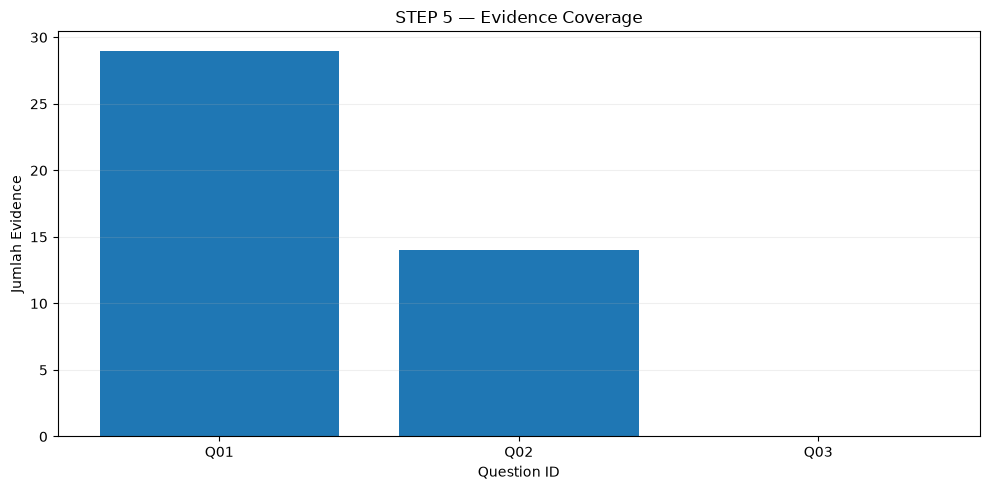

In [43]:
# 5.10 — VISUALISASI EVIDENCE COVERAGE
fig,ax=plt.subplots(figsize=(10,5))
ax.bar(batch_evaluation["id"],batch_evaluation["evidence"])
ax.set_title("STEP 5 — Evidence Coverage")
ax.set_xlabel("Question ID"); ax.set_ylabel("Jumlah Evidence")
ax.grid(axis="y",alpha=.2)
plt.tight_layout(); plt.show()

# STEP 5 CHECKPOINT — EVALUASI END-TO-END

Evaluasi mencakup evidence availability, traceability, numerical grounding screening, unsupported query, abstention, batch evaluation, evaluasi manual, dan visualisasi evidence coverage.

> Screening otomatis membantu pemeriksaan, tetapi tidak digunakan untuk mengklaim bahwa seluruh jawaban GenAI pasti benar secara semantik.

# STEP 6 — FINISHING DAN DEMO AKHIR

Tahap terakhir merangkum pipeline menjadi satu demo yang siap digunakan untuk presentasi. Tidak ada metode baru yang ditambahkan.

**Pertanyaan → Graph Retrieval → Evidence → Grounded Context → GenAI → Jawaban + Provenance**

In [44]:
# 6.1 — FINAL DEMO
def final_demo(question,profil_id=None,jenis=None,urusan=None,limit=10):
    evidence=build_graph_evidence(profile_id=profil_id,jenis=jenis,urusan=urusan,limit=limit)
    context=build_grounded_context(evidence)
    answer=generate_grounded_answer(question,context)
    return {"question":question,"evidence":evidence,"context":context,"answer":answer}

final_demo_result=final_demo(
    f"Apa karakteristik {_g_name(eval_profile)} berdasarkan data Knowledge Graph?",
    profil_id=eval_profile
)
print("Status:",final_demo_result["answer"].get("status"))
if final_demo_result["answer"].get("answer"):
    print("\n=== JAWABAN ===\n",final_demo_result["answer"]["answer"])
print("\nJumlah profile evidence:",len(final_demo_result["evidence"]["profile_evidence"]))
print("Jumlah innovation evidence:",len(final_demo_result["evidence"]["innovation_evidence"]))

Status: not_executed

Jumlah profile evidence: 9
Jumlah innovation evidence: 10


In [45]:
# 6.2 — PROVENANCE FINAL
def final_provenance(evidence):
    rows=[]
    for e in evidence.get("profile_evidence",[]):
        rows.append({"source":e.get("source"),"relationship":e.get("relationship"),
                     "target":e.get("target"),"percentage":e.get("percentage"),
                     "count":e.get("count")})
    for p in evidence.get("paths",[]):
        rows.append({"source":"TRAVERSAL","relationship":"PATH","target":p,
                     "percentage":None,"count":None})
    return pd.DataFrame(rows)

display(final_provenance(final_demo_result["evidence"]).head(30))

,source,relationship,target,percentage,count
0,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,Teknologi,46.0,23.0
1,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,Non Digital,40.0,20.0
2,Profil Ekosistem Wilayah 1,DOMINAN_JENIS,Digital,14.0,7.0
3,Profil Ekosistem Wilayah 1,DOMINAN_URUSAN,kesehatan,66.0,33.0
4,Profil Ekosistem Wilayah 1,DOMINAN_URUSAN,pendidikan,34.0,17.0
5,Profil Ekosistem Wilayah 1,DOMINAN_TAHAPAN,Penerapan,100.0,50.0
6,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,Inovasi pelayanan publik,90.0,45.0
7,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,Inovasi Daerah lainnya sesuai dengan Urusan Pe...,6.0,3.0
8,Profil Ekosistem Wilayah 1,DOMINAN_BENTUK,Inovasi tata kelola pemerintahan daerah,4.0,2.0
9,TRAVERSAL,PATH,PROFILE_EKO_01 → DAERAH_14 → INV_0031,NaN,NaN


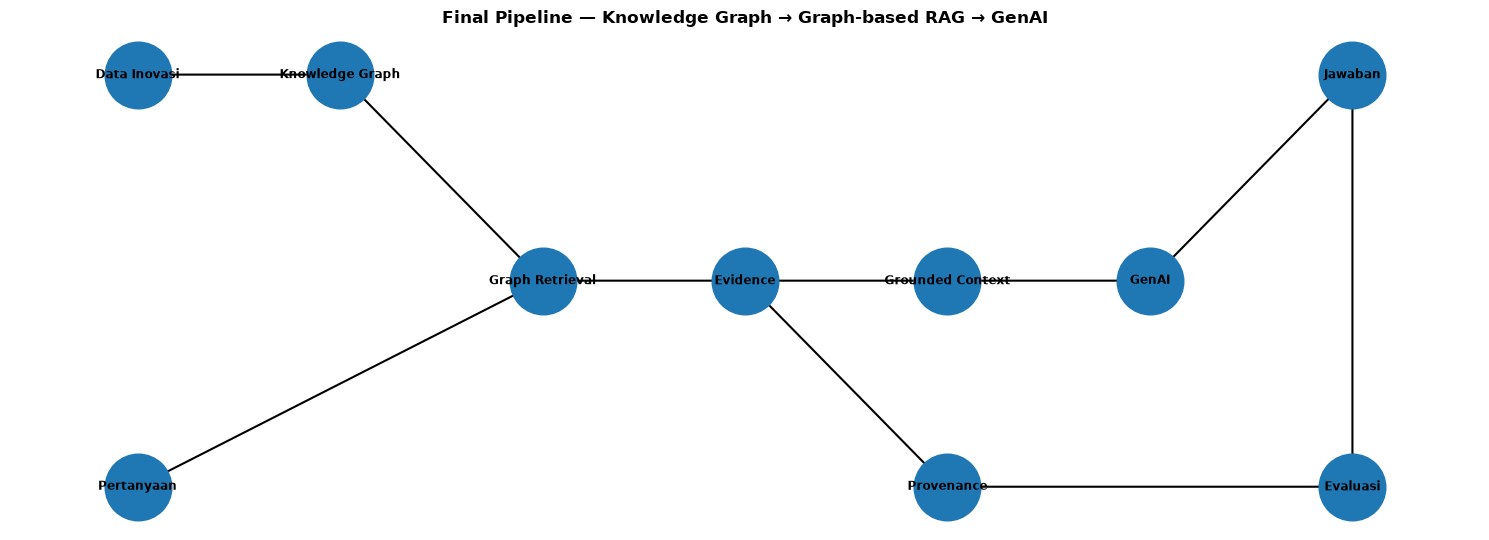

In [46]:
# 6.3 — VISUALISASI FINAL PIPELINE
R=nx.DiGraph()
edges=[
    ("Data Inovasi","Knowledge Graph"),("Knowledge Graph","Graph Retrieval"),
    ("Pertanyaan","Graph Retrieval"),("Graph Retrieval","Evidence"),
    ("Evidence","Grounded Context"),("Grounded Context","GenAI"),
    ("GenAI","Jawaban"),("Evidence","Provenance"),("Jawaban","Evaluasi"),
    ("Provenance","Evaluasi")
]
R.add_edges_from(edges)
pos={"Data Inovasi":(0,1),"Knowledge Graph":(2,1),"Pertanyaan":(0,-1),
     "Graph Retrieval":(4,0),"Evidence":(6,0),"Grounded Context":(8,0),
     "GenAI":(10,0),"Jawaban":(12,1),"Provenance":(8,-1),"Evaluasi":(12,-1)}
fig,ax=plt.subplots(figsize=(15,5.5))
nx.draw_networkx_nodes(R,pos,ax=ax,node_size=2300)
nx.draw_networkx_edges(R,pos,ax=ax,arrows=True,arrowsize=18,width=1.5)
nx.draw_networkx_labels(R,pos,ax=ax,font_size=8.5,font_weight="bold")
ax.set_title("Final Pipeline — Knowledge Graph → Graph-based RAG → GenAI",
             fontsize=12,fontweight="bold")
ax.axis("off"); plt.tight_layout(); plt.show()

In [47]:
# 6.4 — FINAL SYSTEM STATUS
final_status=pd.DataFrame([{
    "knowledge_graph":"tersedia",
    "graph_retrieval":"tersedia",
    "weighted_evidence":"tersedia",
    "grounded_context":"tersedia",
    "genai":"tersedia" if genai_client is not None else "menunggu API key",
    "provenance":"tersedia",
    "evaluation":"tersedia",
    "chatbot_ui":"belum dibuat"
}])
display(final_status)

,knowledge_graph,graph_retrieval,weighted_evidence,grounded_context,genai,provenance,evaluation,chatbot_ui
0,tersedia,tersedia,tersedia,tersedia,menunggu API key,tersedia,tersedia,belum dibuat


# STEP 6 CHECKPOINT — FINISHING

Pipeline akhir:

**Data Inovasi → Knowledge Graph → Graph Retrieval → Evidence → Grounded Context → GenAI → Jawaban → Provenance + Evaluasi**

> Knowledge Graph menjadi sumber fakta dan hubungan. Graph Retrieval memilih evidence yang relevan. Evidence disusun menjadi grounded context. GenAI menyusun context menjadi jawaban natural language, sedangkan provenance memungkinkan jawaban ditelusuri kembali ke graph.

Project berhenti pada pipeline dan evaluasi. Chatbot/UI dapat dibuat sebagai lapisan presentasi terpisah tanpa mengubah inti metode.